# Phân tích dữ liệu fine-tune BGE-M3 (lĩnh vực Lao động)

Notebook kiểm tra chất lượng các cặp (câu hỏi → đoạn luật) trích từ Hugging Face trước khi fine-tune.
Chưa fine-tune ở đây; mục tiêu là quyết định cần lọc/chia dữ liệu thế nào.

**Dữ liệu đang ở đâu**

| Vai trò | File | Nguồn | Trên git? |
|---|---|---|---|
| Train/val (ứng viên) | `data/processed/finetune/tvpl_lao_dong_train.jsonl` | `labor_rag/finetune/extract_tvpl_pairs.py` ← GreenNode/TVPL-Retrieval-VN | Không (gitignore) |
| Train/val (ứng viên) | `data/processed/finetune/tvpl_lao_dong_expanded.jsonl` | `labor_rag/finetune/extract_tvpl_domain_pairs.py` ← TVPL | Không |
| Train/val (ứng viên) | `data/processed/finetune/vlsp_lao_dong_train.jsonl` | `labor_rag/finetune/extract_vlsp_pairs.py` ← longstnguyen/vlsp2025-qa-* (gated, CC BY-NC-SA 4.0) | Không — không được phân phối lại |
| Test (đóng băng) | `labor_rag/evaluation/benchmark_questions_v2.jsonl` | Bộ 150 câu của Bảo | Chỉ ở nhánh `origin/dev/bao` |
| Corpus | `data/processed/lao_dong_v5/chunks.jsonl` | 1481 chunk | Có |

Nội dung:
1. Tổng quan từng nguồn
2. Độ dài câu hỏi / đoạn đúng
3. Văn bản được dẫn và độ phủ corpus v5
4. Nhiễu ngoài lĩnh vực
5. Văn bản hết hiệu lực
6. Đoạn đúng của VLSP có phải văn bản luật gốc?
7. Trùng lặp giữa các nguồn
8. Rò rỉ sang bộ test
9. Kiểm tra tay các cặp ánh xạ v5
10. Kết luận

In [1]:
import json
import re
import subprocess
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "labor_rag" / "config.py").exists())
FT_DIR = ROOT / "data" / "processed" / "finetune"
CHUNKS_PATH = ROOT / "data" / "processed" / "lao_dong_v5" / "chunks.jsonl"
TEST_PATH = ROOT / "labor_rag" / "evaluation" / "benchmark_questions_v2.jsonl"
TEST_GIT_REF = "origin/dev/bao:labor_rag/evaluation/benchmark_questions_v2.jsonl"

# Bảng màu giống notebooks/dataset_analysis.ipynb
INK = "#0b0b0b"
INK_SECOND = "#52514e"
INK_MUTED = "#898781"
GRID = "#e1e0d9"
BASELINE = "#c3c2b7"
SURFACE = "#fcfcfb"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
BLUE = CAT[0]

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": BASELINE,
    "axes.labelcolor": INK_SECOND,
    "text.color": INK,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "grid.color": GRID,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})


def hbar(labels, values, *, color=BLUE, figsize=(8, 4), title="", xlabel="", value_labels=False):
    """Horizontal bar chart using integer y-positions so duplicate labels never merge."""
    fig, ax = plt.subplots(figsize=figsize)
    y = range(len(labels))
    bars = ax.barh(list(y), values, color=color, height=0.6)
    ax.set_yticks(list(y))
    ax.set_yticklabels(labels)
    ax.invert_yaxis()
    ax.set_xlabel(xlabel)
    ax.set_title(title, loc="left", color=INK, fontsize=13, pad=12)
    ax.grid(axis="x", linewidth=0.6)
    ax.set_axisbelow(True)
    ax.spines["left"].set_visible(False)
    ax.tick_params(left=False)
    if value_labels:
        xmax = max(values) if len(values) else 0
        for bar, val in zip(bars, values):
            ax.text(bar.get_width() + xmax * 0.01, bar.get_y() + bar.get_height() / 2,
                    f"{val:,}", va="center", color=INK_SECOND, fontsize=9)
    plt.tight_layout()
    return fig, ax


def load_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


def load_test():
    """Bộ test 150 câu: lấy file local nếu có, nếu không đọc từ nhánh dev/bao."""
    if TEST_PATH.exists():
        return load_jsonl(TEST_PATH)
    out = subprocess.run(["git", "show", TEST_GIT_REF], cwd=ROOT, capture_output=True, check=True)
    return [json.loads(line) for line in out.stdout.decode("utf-8").splitlines() if line.strip()]


def norm(s):
    return re.sub(r"\W+", " ", s.lower()).strip()


def toks(s):
    return set(norm(s).split())


def jaccard(a, b):
    return len(a & b) / len(a | b) if a | b else 0.0

## 1. Tổng quan từng nguồn

In [2]:
chunks = {c["chunk_id"]: c for c in load_jsonl(CHUNKS_PATH)}
test = load_test()

tvpl_v5 = load_jsonl(FT_DIR / "tvpl_lao_dong_train.jsonl")
tvpl_exp = load_jsonl(FT_DIR / "tvpl_lao_dong_expanded.jsonl")
vlsp = load_jsonl(FT_DIR / "vlsp_lao_dong_train.jsonl")


def positive_text(r):
    """TVPL-v5 chỉ lưu chunk_id; hai file còn lại lưu toàn văn đoạn đúng."""
    if r.get("positive_text"):
        return r["positive_text"]
    return "\n".join(chunks[c]["text"] for c in r.get("positive_chunk_ids", []) if c in chunks)


SOURCES = {"TVPL-v5": tvpl_v5, "TVPL-mở rộng": tvpl_exp, "VLSP": vlsp}
rows = []
for name, data in SOURCES.items():
    rows.append({
        "nguồn": name,
        "số cặp": len(data),
        "câu hỏi khác nhau": len({norm(r["query"]) for r in data}),
        "ánh xạ được vào v5": sum(1 for r in data if r.get("positive_chunk_ids")),
        "chunk v5 khác nhau": len({c for r in data for c in r.get("positive_chunk_ids", [])}),
        "trường": ", ".join(data[0].keys()),
    })
overview = pd.DataFrame(rows)
print(f"Corpus v5: {len(chunks)} chunk | Test: {len(test)} câu")
overview

Corpus v5: 1481 chunk | Test: 150 câu


,nguồn,số cặp,câu hỏi khác nhau,ánh xạ được vào v5,chunk v5 khác nhau,trường
0,TVPL-v5,136,136,136,95,"id, query, positive_chunk_ids, document_id, meta_dieu, corpus_id, source"
1,TVPL-mở rộng,745,745,80,59,"id, query, positive_text, positive_title, positive_chunk_ids, corpus_id, matched_reason, source"
2,VLSP,654,654,57,36,"id, query, positive_text, positive_chunk_ids, document_id, meta_dieu, matched_citation, matched_reason, source"


## 2. Độ dài câu hỏi và đoạn đúng (số từ)

BGE-M3 xử lý được 8192 token, nhưng khi fine-tune thường đặt `max_len` 512–1024. Tiếng Việt khoảng 1.3 token/từ, nên đoạn > ~400 từ sẽ bị cắt ở 512 token.

query                                      positive                                          
              count  mean   std   min   50%   90%    max    count   mean    std   min    50%    90%     max
nguồn                                                                                                      
TVPL-mở rộng  745.0  20.0   6.0   6.0  19.0  28.0   46.0    745.0  240.0  149.0  25.0  211.0  426.0  1365.0
TVPL-v5       136.0  19.0   7.0   7.0  18.0  27.0   38.0    136.0  340.0  199.0  55.0  281.0  734.0   834.0
VLSP          654.0  52.0  17.0  11.0  50.0  75.0  124.0    654.0   80.0   45.0   9.0   72.0  131.0   581.0

Tỉ lệ đoạn đúng > 400 từ: {'TVPL-mở rộng': 12.2, 'TVPL-v5': 25.0, 'VLSP': 0.2}


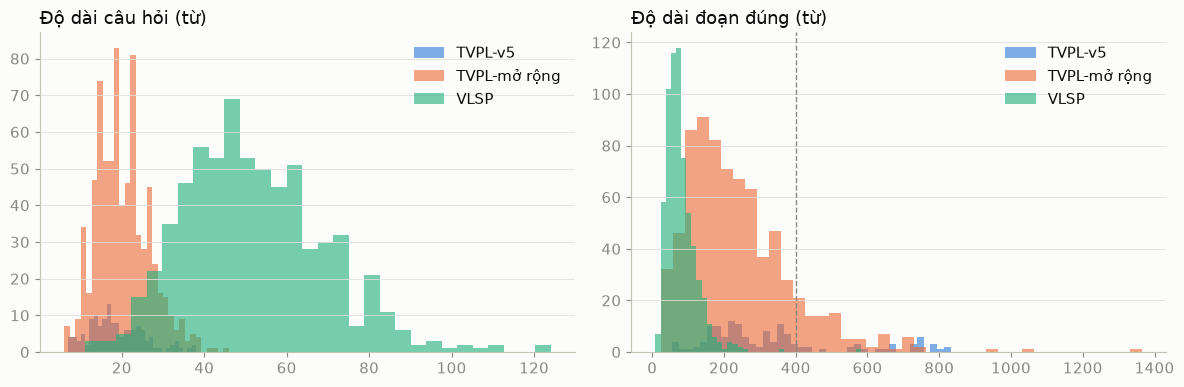

In [3]:
len_rows = []
for name, data in SOURCES.items():
    for r in data:
        len_rows.append({"nguồn": name, "query": len(r["query"].split()), "positive": len(positive_text(r).split())})
lens = pd.DataFrame(len_rows)
display(lens.groupby("nguồn").describe(percentiles=[.5, .9]).round(0))
print("Tỉ lệ đoạn đúng > 400 từ:", (lens.assign(dai=lens.positive > 400).groupby("nguồn").dai.mean() * 100).round(1).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for i, (name, _) in enumerate(SOURCES.items()):
    sub = lens[lens["nguồn"] == name]
    axes[0].hist(sub["query"], bins=30, alpha=0.6, color=CAT[i], label=name)
    axes[1].hist(sub["positive"], bins=40, alpha=0.6, color=CAT[i], label=name)
axes[0].set_title("Độ dài câu hỏi (từ)", loc="left")
axes[1].set_title("Độ dài đoạn đúng (từ)", loc="left")
axes[1].axvline(400, color=INK_MUTED, linestyle="--", linewidth=1)
for ax in axes:
    ax.legend(frameon=False)
    ax.grid(axis="y", linewidth=0.6)
plt.tight_layout()

## 3. Văn bản được dẫn và độ phủ corpus v5

,chunk corpus,chunk có câu hỏi train,chunk đáp án test,đáp án test có câu hỏi train
20.2,512,84,62,10
20.3,190,7,23,1
20.4,423,17,37,1
20.5,353,18,69,13
Tổng,1478,126,191,25


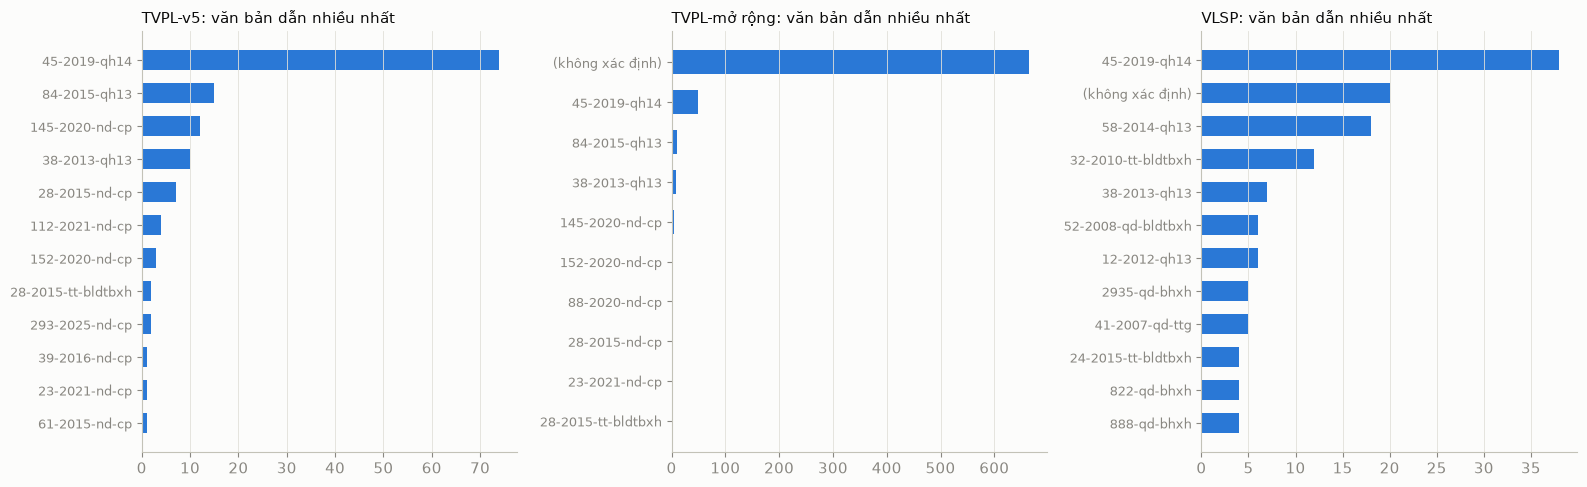

In [4]:
def doc_of(r):
    if r.get("document_id"):
        return r["document_id"]
    ids = r.get("positive_chunk_ids") or []
    return ids[0].split(":")[0] if ids else "(không xác định)"


fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, data) in zip(axes, SOURCES.items()):
    top = Counter(doc_of(r) for r in data).most_common(12)
    ax.barh(range(len(top)), [v for _, v in top], color=BLUE, height=0.6)
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels([k for k, _ in top], fontsize=9)
    ax.invert_yaxis()
    ax.set_title(f"{name}: văn bản dẫn nhiều nhất", loc="left", fontsize=11)
    ax.grid(axis="x", linewidth=0.6)
plt.tight_layout()

de_muc = lambda cid: ".".join(chunks[cid]["mapc"].split(".")[:2]) if cid in chunks else "?"
corpus_dm = Counter(de_muc(c) for c in chunks)
test_gold = {c for t in test for c in t.get("chunk_relevance", {})}
all_pos = {c for data in SOURCES.values() for r in data for c in r.get("positive_chunk_ids", [])}
cov = pd.DataFrame({
    "chunk corpus": pd.Series(corpus_dm),
    "chunk có câu hỏi train": pd.Series(Counter(de_muc(c) for c in all_pos)),
    "chunk đáp án test": pd.Series(Counter(de_muc(c) for c in test_gold)),
    "đáp án test có câu hỏi train": pd.Series(Counter(de_muc(c) for c in test_gold & all_pos)),
}).fillna(0).astype(int)
cov = cov[cov.index.str.match(r"^20\.\d$")]
cov.loc["Tổng"] = cov.sum()
cov

## 4. Nhiễu ngoài lĩnh vực

Bộ lọc của script dựa trên regex (`doc_match`, `subject_and_action`, `strong_term`). Kiểm tra hai heuristic: câu hỏi về khu vực công (công chức/viên chức/quân đội/công an) và câu hỏi không có từ khoá lao động nào.

In [5]:
PUBLIC = r"công chức|viên chức|quân nhân|công an|sĩ quan|cán bộ|quân đội"
LABOR_KW = r"lao động|lương|bảo hiểm|việc làm|thai sản|công đoàn|thất nghiệp|hưu|thử việc|sa thải|nghỉ|làm việc|tuyển|thôi việc|tai nạn"

noise_rows = []
for name, data in SOURCES.items():
    reasons = Counter((r.get("matched_reason") or "map_v5").split(":")[0] for r in data)
    noise_rows.append({
        "nguồn": name,
        "khu vực công": sum(1 for r in data if re.search(PUBLIC, r["query"].lower())),
        "không có từ khoá LĐ": sum(1 for r in data if not re.search(LABOR_KW, r["query"].lower())),
        **{f"lý do: {k}": v for k, v in reasons.items()},
    })
display(pd.DataFrame(noise_rows).fillna(0))

for name in ["TVPL-mở rộng", "VLSP"]:
    nolab = [r["query"] for r in SOURCES[name] if not re.search(LABOR_KW, r["query"].lower())]
    print(f"\n{name} — ví dụ câu không có từ khoá lao động ({len(nolab)}):")
    for q in nolab[:10]:
        print("  -", q[:160].replace("\n", " "))

,nguồn,khu vực công,không có từ khoá LĐ,lý do: map_v5,lý do: subject_and_action,lý do: doc_match,lý do: strong_term
0,TVPL-v5,3,7,136.0,0.0,0.0,0.0
1,TVPL-mở rộng,60,171,0.0,388.0,273.0,84.0
2,VLSP,70,135,0.0,163.0,445.0,46.0



TVPL-mở rộng — ví dụ câu không có từ khoá lao động (171):
  - Tiêu chuẩn và điều kiện dự thi nâng ngạch công chức là gì?
  - Nhiệm vụ của Ủy ban Nhà nước về người Việt Nam ở nước ngoài là gì?
  - Quỹ Trò nghèo vùng cao có tư cách pháp nhân và có con dấu riêng không?
  - Xúi giục người khác tự sát để được hưởng án treo cần đáp ứng điều kiện gì?
  - Chuyên gia tham gia khảo sát thực tế và tư vấn cho đoàn đánh giá ngoài cơ sở giáo dục nghề nghiệp cần điều kiện như thế nào?
  - Tiêu chuẩn đối với chức danh nhân viên phục vụ chạy tàu đường sắt đô thị tại ga là gì?
  - Điều kiện thành lập công ty chuyên cung cấp dịch vụ kế toán cho nước ngoài được quy định như thế nào?
  - Chủ tịch Ủy ban nhân dân thành phố Hà Nội có được hưởng chế độ phụ cấp phục vụ không?
  - Người làm công việc dệt len thủ công có các quyền hạn nào?
  - Quỹ Từ thiện Ngã Ba Đồng Lộc hoạt động theo nguyên tắc nào?

VLSP — ví dụ câu không có từ khoá lao động (135):
  - Một nhóm người muốn thành lập một tổ chức để bảo vệ quy

## 5. Văn bản hết hiệu lực

Câu hỏi cũ thường dẫn BLLĐ 2012 (10/2012/QH13), NĐ 05/2015… Dạy model khớp câu hỏi với quy định cũ sẽ đưa tới trả lời sai luật hiện hành. Corpus v5 chỉ chứa văn bản còn hiệu lực.

In [6]:
OLD = r"10/2012/qh13|10-2012-qh13|bộ luật lao động (năm )?2012|05/2015/nđ-cp|05-2015-nd-cp|luật bảo hiểm xã hội (năm )?2006|71/2006/qh11"
v5_docs = {c["document_id"] for c in chunks.values()}
old_rows = []
for name, data in SOURCES.items():
    txt = lambda r: (r["query"] + " " + positive_text(r) + " " + (r.get("document_id") or "")).lower()
    old_rows.append({
        "nguồn": name,
        "nhắc văn bản cũ": sum(1 for r in data if re.search(OLD, txt(r))),
        "dẫn văn bản không có trong v5": sum(1 for r in data if r.get("document_id") and r["document_id"] not in v5_docs),
    })
pd.DataFrame(old_rows)

,nguồn,nhắc văn bản cũ,dẫn văn bản không có trong v5
0,TVPL-v5,0,0
1,TVPL-mở rộng,2,0
2,VLSP,2,563


In [7]:
outside = Counter(r["document_id"] for r in vlsp if r.get("document_id") and r["document_id"] not in v5_docs)
print("VLSP — văn bản được dẫn nhưng không có trong corpus v5 (top 15):")
pd.Series(dict(outside.most_common(15)), name="số câu").to_frame()

VLSP — văn bản được dẫn nhưng không có trong corpus v5 (top 15):


,số câu
58-2014-qh13,18
32-2010-tt-bldtbxh,12
52-2008-qd-bldtbxh,6
12-2012-qh13,6
2935-qd-bhxh,5
41-2007-qd-ttg,5
24-2015-tt-bldtbxh,4
822-qd-bhxh,4
888-qd-bhxh,4
584-qd-ldtbxh,4


## 6. Đoạn đúng của VLSP có phải văn bản luật gốc?

VLSP lưu "Tiền đề lớn" trong lời giải làm đoạn đúng. Nếu đó là đoạn diễn đạt lại, model sẽ học khớp câu hỏi với văn bản khác kiểu chunk thật. Đo tỉ lệ 8-gram của tiền đề xuất hiện trong chunk v5 được ánh xạ.

In [8]:
def ngram_overlap(a, b, n=8):
    wa, wb = norm(a).split(), norm(b).split()
    ga = {" ".join(wa[i:i + n]) for i in range(len(wa) - n + 1)}
    gb = {" ".join(wb[i:i + n]) for i in range(len(wb) - n + 1)}
    return len(ga & gb) / len(ga) if ga else 0.0


mapped = [r for r in vlsp if r["positive_chunk_ids"]]
ov = pd.Series([ngram_overlap(r["positive_text"], "\n".join(chunks[c]["text"] for c in r["positive_chunk_ids"])) for r in mapped])
print(f"VLSP ánh xạ v5: {len(mapped)} cặp; tỉ lệ 8-gram tiền đề nằm trong chunk: trung vị {ov.median():.2f}, "
      f"≥0.5: {(ov >= .5).sum()}, <0.2: {(ov < .2).sum()}")
print("Tiền đề bắt đầu bằng 'Theo'/'Căn cứ':", sum(1 for r in vlsp if re.match(r"\s*(theo|căn cứ)", r["positive_text"].lower())), "/", len(vlsp))
print("\nVí dụ:")
for r in vlsp[:4]:
    print("Q:", r["query"][:200].replace("\n", " "))
    print("  Tiền đề:", r["positive_text"][:300].replace("\n", " "))
    print("  Dẫn:", r["matched_citation"], "| v5:", r["positive_chunk_ids"][:2], "\n")

VLSP ánh xạ v5: 57 cặp; tỉ lệ 8-gram tiền đề nằm trong chunk: trung vị 0.00, ≥0.5: 5, <0.2: 49
Tiền đề bắt đầu bằng 'Theo'/'Căn cứ': 584 / 654

Ví dụ:
Q: Vào ngày 01/01/2025, Bộ Lao động - Thương binh và Xã hội gửi báo cáo về tình hình phòng, chống mại dâm cho Bộ Công an. Tuy nhiên, báo cáo này không đầy đủ thông tin theo yêu cầu. Hỏi Bộ Công an có trá
  Tiền đề: Điều 14, khoản 2 của Quyết định 155/2007/QĐ-TTg quy định cơ quan phối hợp có trách nhiệm gửi báo cáo đến cơ quan chủ trì. Khoản 1, Điều 14 quy định cơ quan chủ trì có trách nhiệm tổ chức sơ kết, tổng kết, đánh giá các nội dung hoạt động phối hợp. Tiền đề nhỏ: Bộ Lao động - Thương binh và Xã hội là c
  Dẫn: Điều 14 155/2007/QĐ-TTG | v5: [] 

Q: Một công ty có người lao động bị tai nạn lao động và đã nộp đầy đủ hồ sơ theo quy định để hưởng chế độ bảo hiểm. Tuy nhiên, cơ quan Bảo hiểm xã hội (BHXH) thông báo rằng hồ sơ chưa đầy đủ và yêu cầu b
  Tiền đề: Theo Quyết định 1107/QĐ-LĐTBXH, cơ quan BHXH có trách nhiệm giải quyết hưởng

## 7. Trùng lặp giữa các nguồn

In [9]:
qsets = {name: {norm(r["query"]) for r in data} for name, data in SOURCES.items()}
names = list(qsets)
dup = pd.DataFrame([[len(qsets[a] & qsets[b]) for b in names] for a in names], index=names, columns=names)
print("Số câu hỏi trùng nguyên văn (sau chuẩn hoá):")
display(dup)

# Gần trùng giữa VLSP và TVPL-mở rộng
tv = [toks(r["query"]) for r in tvpl_exp]
near = sum(1 for r in vlsp if max(jaccard(toks(r["query"]), t) for t in tv) >= 0.6)
print(f"VLSP gần trùng (jaccard ≥ 0.6) với TVPL-mở rộng: {near}")
union = qsets["TVPL-mở rộng"] | qsets["TVPL-v5"] | qsets["VLSP"]
print(f"Tổng câu hỏi khác nhau sau khi gộp 3 nguồn: {len(union)}")

Số câu hỏi trùng nguyên văn (sau chuẩn hoá):


,TVPL-v5,TVPL-mở rộng,VLSP
TVPL-v5,136,128,0
TVPL-mở rộng,128,745,0
VLSP,0,0,654


VLSP gần trùng (jaccard ≥ 0.6) với TVPL-mở rộng: 0
Tổng câu hỏi khác nhau sau khi gộp 3 nguồn: 1407


## 8. Rò rỉ sang bộ test

Script chỉ loại câu trùng nguyên văn với benchmark v1 (30 câu); bộ 150 câu v2 không được loại. Đo jaccard từ của mỗi câu train tới câu test gần nhất.

              ≥0.5  ≥0.6   max
nguồn                         
TVPL-mở rộng     4     2  0.75
TVPL-v5          1     1  0.71
VLSP             0     0  0.40


,nguồn,jaccard,test_id,cùng đáp án,câu train,câu test
500,TVPL-mở rộng,0.75,q19,False,Để được hưởng chế độ ốm đau thì người lao động cần đáp ứng những điều kiện nào?,Người lao động cần đáp ứng những điều kiện nào để được hưởng chế độ tai nạn lao động?
311,TVPL-mở rộng,0.71,q19,True,Điều kiện để người lao động được hưởng chế độ tai nạn lao động?,Người lao động cần đáp ứng những điều kiện nào để được hưởng chế độ tai nạn lao động?
88,TVPL-v5,0.71,q19,True,Điều kiện để người lao động được hưởng chế độ tai nạn lao động?,Người lao động cần đáp ứng những điều kiện nào để được hưởng chế độ tai nạn lao động?
826,TVPL-mở rộng,0.50,ld018,False,"Trong thời gian đình công, người lao động có được hưởng lương không?","Trong thời gian người lao động đình công, doanh nghiệp có những quyền gì?"
348,TVPL-mở rộng,0.50,q19,False,Để được hưởng chế độ thai sản cần đáp ứng điều kiện gì?,Người lao động cần đáp ứng những điều kiện nào để được hưởng chế độ tai nạn lao động?
424,TVPL-mở rộng,0.47,q15,True,Khai báo tai nạn lao động được quy định thế nào?,"Tai nạn lao động và sự cố kỹ thuật phải được khai báo, báo cáo như thế nào?"
107,TVPL-v5,0.47,q15,True,Khai báo tai nạn lao động được quy định thế nào?,"Tai nạn lao động và sự cố kỹ thuật phải được khai báo, báo cáo như thế nào?"
58,TVPL-v5,0.45,q13,True,Máy móc có yêu cầu nghiêm ngặt về an toàn vệ sinh lao động có phải máy móc dùng cho các công việc có yêu cầu n,"Máy móc, thiết bị, vật tư hoặc chất nào được xem là có yêu cầu nghiêm ngặt về an toàn, vệ sinh lao động?"
63,TVPL-v5,0.45,q09,False,Kỳ hạn trả lương cho người lao động được quy định như thế nào?,Người lao động được khám sức khỏe định kỳ với tần suất như thế nào?
719,TVPL-mở rộng,0.45,q09,False,Kỳ hạn trả lương cho người lao động được quy định như thế nào?,Người lao động được khám sức khỏe định kỳ với tần suất như thế nào?


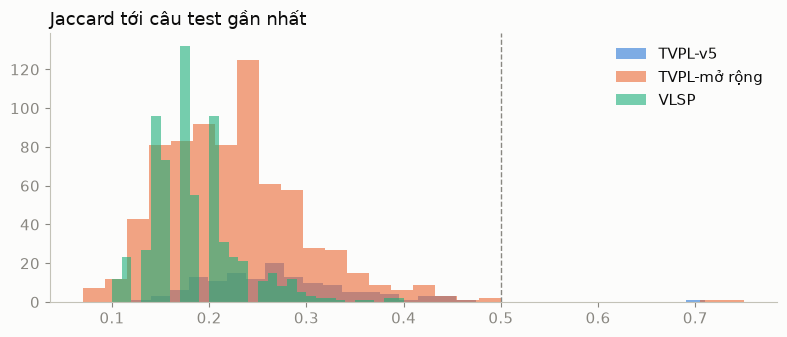

In [10]:
test_toks = [(toks(t["question"]), t) for t in test]
leak_rows = []
for name, data in SOURCES.items():
    for r in data:
        qt = toks(r["query"])
        j, t = max(((jaccard(qt, tt), t) for tt, t in test_toks), key=lambda z: z[0])
        same_gold = bool(set(r.get("positive_chunk_ids", [])) & set(t.get("chunk_relevance", {})))
        leak_rows.append({"nguồn": name, "jaccard": round(j, 2), "test_id": t["id"], "cùng đáp án": same_gold,
                          "câu train": r["query"][:110], "câu test": t["question"][:110]})
leak = pd.DataFrame(leak_rows).sort_values("jaccard", ascending=False)
print(leak.groupby("nguồn").jaccard.agg(**{"≥0.5": lambda s: (s >= .5).sum(), "≥0.6": lambda s: (s >= .6).sum(), "max": "max"}))

fig, ax = plt.subplots(figsize=(8, 3.5))
for i, name in enumerate(SOURCES):
    ax.hist(leak[leak["nguồn"] == name].jaccard, bins=30, alpha=0.6, color=CAT[i], label=name)
ax.axvline(0.5, color=INK_MUTED, linestyle="--", linewidth=1)
ax.set_title("Jaccard tới câu test gần nhất", loc="left")
ax.legend(frameon=False)
plt.tight_layout()

leak.head(12)

In [11]:
gold_hit = {name: len(test_gold & {c for r in data for c in r.get("positive_chunk_ids", [])}) for name, data in SOURCES.items()}
print(f"Chunk đáp án test: {len(test_gold)}; trùng với chunk đáp án train: {gold_hit}")

Chunk đáp án test: 191; trùng với chunk đáp án train: {'TVPL-v5': 23, 'TVPL-mở rộng': 14, 'VLSP': 2}


## 9. Kiểm tra tay các cặp ánh xạ v5

Ngẫu nhiên 15 cặp đã ánh xạ vào chunk v5: câu hỏi và tiêu đề Điều được gán. Đọc để ước lượng tỉ lệ ánh xạ sai.

In [12]:
import random

rng = random.Random(0)
pool = [(n, r) for n, d in SOURCES.items() for r in d if r.get("positive_chunk_ids")]
check = []
for name, r in rng.sample(pool, min(15, len(pool))):
    cid = r["positive_chunk_ids"][0]
    check.append({"nguồn": name, "câu hỏi": r["query"][:110], "chunk": cid,
                  "Điều được gán": chunks[cid]["text"].split("\n")[1][:80], "số chunk đúng": len(r["positive_chunk_ids"])})
pd.DataFrame(check)

,nguồn,câu hỏi,chunk,Điều được gán,số chunk đúng
0,TVPL-mở rộng,"Tiền lương làm thêm giờ, làm việc vào ban đêm sẽ được trả theo nguyên tắc nào?",45-2019-qh14:d98,"Điều 98. Tiền lương làm thêm giờ, làm việc vào ban đêm",1
1,TVPL-mở rộng,Thay đổi về mức lương tối thiểu vùng thì có phải ký lại hợp đồng lao động không?,45-2019-qh14:d21,Điều 21. Nội dung hợp đồng lao động,1
2,TVPL-v5,Lương tối thiểu theo giờ là gì?,45-2019-qh14:d91,Điều 91. Mức lương tối thiểu,1
3,TVPL-v5,Thời gian nghỉ tai nạn lao động có được tính số ngày nghỉ phép năm không?,145-2020-nd-cp:d65,Điều 65. Thời gian được coi là thời gian làm việc để tính số ngày nghỉ hằng năm,1
4,VLSP,Một doanh nghiệp có nhiều lao động nữ đang muốn được hưởng ưu đãi về thuế. Hãy cho biết doanh nghiệp cần phải,45-2019-qh14:d110,Điều 110. Nghỉ chuyển ca,1
5,VLSP,Ông A là người lao động làm việc tại Công ty Quản lý tài sản của các tổ chức tín dụng Việt Nam theo hợp đồng l,45-2019-qh14:d2,Điều 2. Đối tượng áp dụng,1
6,TVPL-mở rộng,Người lao động chết do bệnh khi đang làm việc thì thân nhân được hưởng trợ cấp không?,84-2015-qh13:d53,"Điều 53. Trợ cấp khi người lao động chết do tai nạn lao động, bệnh nghề nghiệp",1
7,TVPL-mở rộng,Điều kiện để người lao động được hưởng chế độ tai nạn lao động?,84-2015-qh13:d45,Điều 45. Điều kiện hưởng chế độ tai nạn lao động,1
8,VLSP,Công nhân B làm nghề đặc biệt nặng nhọc cho Công ty Y đã làm việc 15 năm. Hãy xác định số ngày nghỉ hàng năm c,45-2019-qh14:d74,Điều 74. Trách nhiệm của Ủy ban nhân dân cấp tỉnh trong thương lượng tập thể,1
9,TVPL-mở rộng,Hợp đồng cộng tác viên có phải là hợp đồng lao động hay không?,45-2019-qh14:d21,Điều 21. Nội dung hợp đồng lao động,1


## 10. Kết luận

**Quy mô:** gộp 3 nguồn được 1407 câu hỏi khác nhau, nhưng chỉ khoảng 220 cặp gắn được vào chunk v5 (126 chunk, 8.5% corpus). Chỉ 25/191 chunk đáp án test có câu hỏi train. Đề mục 20.3 và 20.4 gần như không có câu hỏi.

**Vấn đề theo nguồn**

| Nguồn | Dùng được | Vấn đề chính |
|---|---|---|
| TVPL-v5 (136) | Tốt nhất: câu hỏi người dân thật, đoạn đúng là chunk v5 | Ít; dồn vào BLLĐ 45/2019; 25% đoạn đúng > 400 từ; có ánh xạ sai (vd. BHXH một lần của công nhân quốc phòng → Điều 219 BLLĐ) |
| TVPL-mở rộng (745) | 128 câu trùng TVPL-v5; ~80 ánh xạ v5 | 171 câu không có từ khoá lao động, 60 câu khu vực công (vd. thi nâng ngạch công chức, quỹ từ thiện) → bộ lọc `subject_and_action` quá lỏng |
| VLSP (654) | Câu hỏi tình huống dài, đa dạng (p50 50 từ) | 563/654 dẫn văn bản **không có trong v5**; "Tiền đề lớn" là **câu diễn giải** (584 câu bắt đầu "Theo…", trung vị 8-gram trùng chunk = 0), không phải văn bản luật; ánh xạ v5 hay sai (vd. "Điều 74" của văn bản khác bị gán vào Điều 74 BLLĐ) |

**Rò rỉ sang test:** không có câu trùng nguyên văn; 3 câu jaccard ≥ 0.6 (quanh test q19). Script chỉ loại câu trùng với benchmark v1, nên bộ 150 câu v2 cần được lọc khi chia.

**Đề xuất trước khi fine-tune**
1. Dùng TVPL-v5 + phần TVPL-mở rộng đã ánh xạ v5 làm lõi; kiểm tay ánh xạ (vài trăm cặp, làm được).
2. VLSP: chỉ giữ câu hỏi, còn đoạn đúng thì thay bằng chunk v5 tìm lại theo (văn bản, Điều) đã sửa parser; bỏ cặp dẫn văn bản ngoài v5.
3. Siết bộ lọc lĩnh vực (bỏ `subject_and_action` đơn thuần, loại khu vực công).
4. Sinh thêm câu hỏi cho 20.3, 20.4 và các chunk chưa có câu hỏi.
5. Chia: test = 150 câu v2 (đóng băng); train/val ≈ 90/10 theo nhóm Điều; loại câu train có jaccard ≥ 0.5 với test.
6. Đào hard negative từ corpus v5 sau khi chia; cắt hoặc tách đoạn > 512 token.

_Nguồn VLSP: VLSP 2025 Legal QA (CC BY-NC-SA 4.0) — cần trích dẫn bài "Can Small Language Models Handle Vietnamese Legal Reasoning? Insights from Multi-Task Evaluation" (VLSP at INLG 2025) khi dùng._
